<a href="https://colab.research.google.com/github/rifanamer36-max/saudi-road-safety-analysis/blob/main/Saudi_road_safety_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Saudi Road Safety 2014–2023: Deaths Fell 41%, Yet Ambulance Calls Tripled. Why?

**Question:** Road deaths in Saudi Arabia have fallen sharply over the last decade. Why did ambulance calls for traffic accidents in the Makkah region keep rising over the same period?

## Data sources
Both datasets come from the Saudi Open Data Platform (https://open.data.gov.sa), downloaded on 14 October 2026:

1. **Injuries and Deaths from Road Traffic Accidents in the Last Ten Years** (national, 2014–2023). Published by the Ministry of Health. Contains injuries, deaths, and rates per 100,000 population.
2. **Total Ambulance Reports for Road Traffic Accidents in Makkah Region, 2018–2024** (regional, yearly totals). Published by the Saudi Red Crescent Authority.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

NATIONAL_FILE = "national.xlsx"
MAKKAH_FILE = "makkah.xlsx"


In [2]:
def to_num(s):
    table = str.maketrans("٠١٢٣٤٥٦٧٨٩٬٫", "0123456789,.")
    cleaned = s.astype(str).str.translate(table).str.replace(",", "", regex=False)
    return pd.to_numeric(cleaned, errors="coerce")

In [3]:
nat = pd.read_excel(NATIONAL_FILE, header=1)
nat = nat.iloc[:, :5]
nat.columns = ["year", "injuries", "deaths", "injuries_per_100k", "deaths_per_100k"]

for col in nat.columns:
    nat[col] = to_num(nat[col])

nat = nat.dropna(subset=["year"]).reset_index(drop=True)
nat["year"] = nat["year"].astype(int)
nat

,year,injuries,deaths,injuries_per_100k,deaths_per_100k
0,2014,35843,7486,126.612223,26.443632
1,2015,36302,8063,121.751861,27.042181
2,2016,38120,8759,123.149694,28.296647
3,2017,33199,7218,107.171836,23.300892
4,2018,30217,5787,100.068614,19.164612
5,2019,32910,5754,109.467203,19.139298
6,2020,25561,4618,81.010988,14.635920
7,2021,25512,4652,82.873189,15.111558
8,2022,24446,4555,75.977715,14.156856
9,2023,24002,4423,70.874792,13.060545


In [4]:
mk_raw = pd.read_excel(MAKKAH_FILE, header=1)
mk_raw.head()

,م,المنطقة,2018,2019,2020,2021,2022,2023,2024
0,1,مكة المكرمة,23588,50511,42421,60964,71592,75872,81480
1,الإجمالي,NaN,23588,50511,42421,60964,71592,75872,81480


In [5]:
mk = mk_raw[mk_raw.iloc[:, 1].astype(str).str.contains("مكة", na=False)]
mk = mk.iloc[:, 2:].T.reset_index()
mk.columns = ["year", "ambulance_calls"]
mk["year"] = to_num(mk["year"]).astype(int)
mk["ambulance_calls"] = to_num(mk["ambulance_calls"])
mk

,year,ambulance_calls
0,2018,23588
1,2019,50511
2,2020,42421
3,2021,60964
4,2022,71592
5,2023,75872
6,2024,81480


In [6]:
df = nat.merge(mk, on="year", how="left")
df["deaths_per_injury_pct"] = df["deaths"] / df["injuries"] * 100
df["implied_population_m"] = df["injuries"] / df["injuries_per_100k"] * 100_000 / 1e6
df["deaths_yoy_pct"] = df["deaths"].pct_change() * 100
df.round(2)

,year,injuries,deaths,injuries_per_100k,deaths_per_100k,ambulance_calls,deaths_per_injury_pct,implied_population_m,deaths_yoy_pct
0,2014,35843,7486,126.61,26.44,NaN,20.89,28.31,NaN
1,2015,36302,8063,121.75,27.04,NaN,22.21,29.82,7.71
2,2016,38120,8759,123.15,28.30,NaN,22.98,30.95,8.63
3,2017,33199,7218,107.17,23.30,NaN,21.74,30.98,-17.59
4,2018,30217,5787,100.07,19.16,23588.0,19.15,30.20,-19.83
5,2019,32910,5754,109.47,19.14,50511.0,17.48,30.06,-0.57
6,2020,25561,4618,81.01,14.64,42421.0,18.07,31.55,-19.74
7,2021,25512,4652,82.87,15.11,60964.0,18.23,30.78,0.74
8,2022,24446,4555,75.98,14.16,71592.0,18.63,32.18,-2.09
9,2023,24002,4423,70.87,13.06,75872.0,18.43,33.87,-2.90


In [7]:
first, last = df.iloc[0], df.iloc[-1]
print(f"Deaths: {first.deaths:,.0f} -> {last.deaths:,.0f} ({(last.deaths/first.deaths-1)*100:.1f}%)")
print(f"Deaths per 100k: {first.deaths_per_100k} -> {last.deaths_per_100k} ({(last.deaths_per_100k/first.deaths_per_100k-1)*100:.1f}%)")
print(f"Peak year for deaths: {int(df.loc[df.deaths.idxmax(), 'year'])}")

Deaths: 7,486 -> 4,423 (-40.9%)
Deaths per 100k: 26.443632091859087 -> 13.060545209108245 (-50.6%)
Peak year for deaths: 2016


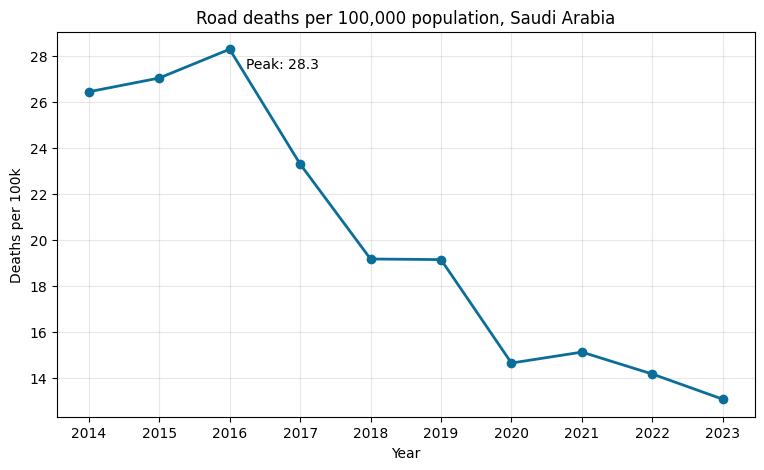

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df["year"], df["deaths_per_100k"], marker="o", linewidth=2, color="#0B6E99")
ax.set_title("Road deaths per 100,000 population, Saudi Arabia")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100k")
ax.set_xticks(df["year"])
ax.grid(alpha=0.3)
peak = df.loc[df["deaths_per_100k"].idxmax()]
ax.annotate(f"Peak: {peak.deaths_per_100k:.1f}", (peak.year, peak.deaths_per_100k),
            textcoords="offset points", xytext=(12, -14))
fig.savefig("deaths_rate.png", dpi=200, bbox_inches="tight")
plt.show()

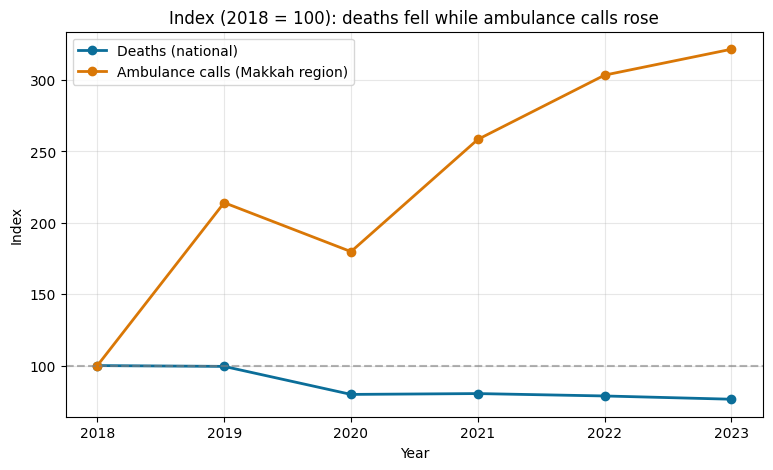

In [9]:
ov = df[df["year"] >= 2018].dropna(subset=["ambulance_calls"]).copy()
ov["deaths_index"] = ov["deaths"] / ov["deaths"].iloc[0] * 100
ov["calls_index"] = ov["ambulance_calls"] / ov["ambulance_calls"].iloc[0] * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ov["year"], ov["deaths_index"], marker="o", linewidth=2, label="Deaths (national)", color="#0B6E99")
ax.plot(ov["year"], ov["calls_index"], marker="o", linewidth=2, label="Ambulance calls (Makkah region)", color="#D97706")
ax.axhline(100, linestyle="--", color="gray", alpha=0.6)
ax.set_title("Index (2018 = 100): deaths fell while ambulance calls rose")
ax.set_xlabel("Year")
ax.set_ylabel("Index")
ax.set_xticks(ov["year"])
ax.legend()
ax.grid(alpha=0.3)
fig.savefig("index_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

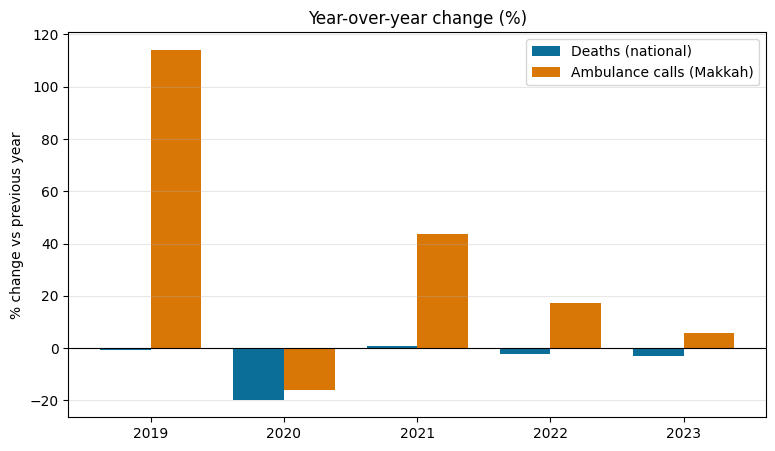

In [10]:
df["calls_yoy_pct"] = df["ambulance_calls"].pct_change(fill_method=None) * 100

yoy = df[df["year"] >= 2019][["year", "deaths_yoy_pct", "calls_yoy_pct"]]
x = list(range(len(yoy)))
w = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar([i - w/2 for i in x], yoy["deaths_yoy_pct"], w, label="Deaths (national)", color="#0B6E99")
ax.bar([i + w/2 for i in x], yoy["calls_yoy_pct"], w, label="Ambulance calls (Makkah)", color="#D97706")
ax.set_xticks(x)
ax.set_xticklabels(yoy["year"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Year-over-year change (%)")
ax.set_ylabel("% change vs previous year")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.savefig("yoy_change.png", dpi=200, bbox_inches="tight")
plt.show()

## Key findings
- National road deaths fell from 7,486 (2014) to 4,423 (2023), a 40.9% drop. Deaths per 100k fell from 26.44 to 13.06 (-50.6%). The peak was in 2016.
- Ambulance calls for traffic accidents in the Makkah region rose from 23,588 (2018) to 81,480 (2024), about 3.45x.
- Calls jumped 114% between 2018 and 2019, which looks more like a change in coverage or reporting than a change on the roads.
- In 2020 both deaths and calls fell (-19.7% and -16.0%). After that they diverged: calls rose 43.7% in 2021 while deaths stayed flat (+0.7%).

###Possible explanations (hypotheses, not tested here)
- Wider ambulance coverage or better call recording.
- Population growth and traffic volume in the region.
- Calls that include minor incidents without injuries.
- Changes in Saudi Red Crescent coverage or reporting practices over time (not verifiable with this data).

## Limitations
- Calls are for the Makkah region only, while deaths are national, so I compare trends, not levels.
- Only 10 yearly points nationally and 7 regionally, so no forecasting or causal claims.
- Implied population (injuries / rate x 100,000) was used only as a consistency check.